# Phase 2 - Layer B: Starlink Gateway Ground Stations

This notebook builds the ground-station layer for the realistic data pipeline. The stations are Starlink gateways: fixed earth-station locations that connect satellites to terrestrial internet infrastructure.

The source dataset is the public Hugging Face `28hery/starlink-ground-stations` dataset. It is practical and well structured, but it should be treated as unofficial: the dataset card describes it as derived from Starlink Insider community data, FCC IBFS filings, and geocoding for stations without coordinates. For this project, those locations are good enough to create physically grounded satellite-to-ground visibility windows later.

This notebook produces a clean gateway table with stable station IDs, names, coordinates, status, source provenance, and a simple country label.

## Configuration

All Layer B files are kept in this `ground-satellites-data` folder. The notebook downloads gateway rows through the Hugging Face dataset-server API using only standard Python plus pandas, then caches the raw rows locally for reproducible reruns.

In [ ]:
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen
import importlib.util
import json
import subprocess
import sys

REQUIRED_PACKAGES = ["pandas"]
missing_packages = [
    package_name
    for package_name in REQUIRED_PACKAGES
    if importlib.util.find_spec(package_name) is None
]

if missing_packages:
    print(f"Installing missing packages into this notebook kernel: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
    print("Dependency installation finished. If imports still fail, restart the kernel and run the notebook again.")

import pandas as pd

DATASET_ID = "28hery/starlink-ground-stations"
DATASET_CONFIG = "gateways"
DATASET_SPLIT = "train"
ROWS_API_URL = "https://datasets-server.huggingface.co/rows"
ROWS_PER_REQUEST = 100
REFRESH_GATEWAY_CACHE = True

DATA_DIR = Path("../../data/dataset/starlink")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_CACHE_PATH = DATA_DIR / "starlink_gateways_raw.json"
OUTPUT_CSV_PATH = DATA_DIR / "starlink_gateways_clean.csv"

print(f"Notebook Python executable: {sys.executable}")
print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Raw cache path: {RAW_CACHE_PATH.resolve()}")
print(f"Output CSV path: {OUTPUT_CSV_PATH.resolve()}")

Notebook Python executable: d:\University\PoliMi\courses\SWE2\SWE2-research-project\.venv\Scripts\python.exe
Data directory: D:\University\PoliMi\courses\SWE2\SWE2-research-project\data\dataset\starlink_ground_stations
Raw cache path: D:\University\PoliMi\courses\SWE2\SWE2-research-project\data\dataset\starlink_ground_stations\starlink_gateways_raw.json
Output CSV path: D:\University\PoliMi\courses\SWE2\SWE2-research-project\data\dataset\starlink_ground_stations\starlink_gateways_clean.csv


## Load Gateway Rows

The loader downloads paginated rows from the Hugging Face dataset-server API. If the local cache already exists, it is reused unless `REFRESH_GATEWAY_CACHE` is set to `True`.

In [2]:
def fetch_huggingface_rows(
    dataset_id: str,
    config: str,
    split: str,
    api_url: str,
    rows_per_request: int,
) -> list[dict]:
    """Download all rows from a Hugging Face dataset-server split.

    Parameters
    ----------
    dataset_id:
        Hugging Face dataset identifier, such as `28hery/starlink-ground-stations`.
    config:
        Dataset configuration name. For this layer, `gateways` is used.
    split:
        Dataset split to download.
    api_url:
        Hugging Face rows endpoint.
    rows_per_request:
        Number of rows requested per API call.

    Returns
    -------
    list[dict]
        Raw row dictionaries from the dataset split.
    """
    all_rows = []
    offset = 0

    while True:
        query = urlencode(
            {
                "dataset": dataset_id,
                "config": config,
                "split": split,
                "offset": offset,
                "length": rows_per_request,
            }
        )
        request_url = f"{api_url}?{query}"

        with urlopen(request_url, timeout=30) as response:
            payload = json.loads(response.read().decode("utf-8"))

        batch = [item["row"] for item in payload.get("rows", [])]
        all_rows.extend(batch)

        if len(batch) < rows_per_request:
            break
        offset += rows_per_request

    return all_rows


def load_gateway_rows(cache_path: Path, refresh_cache: bool = False) -> list[dict]:
    """Load gateway rows from cache or download them from Hugging Face.

    Parameters
    ----------
    cache_path:
        Local JSON path used to store raw gateway rows.
    refresh_cache:
        When True, force a fresh download before reading rows.

    Returns
    -------
    list[dict]
        Raw gateway records with source columns such as name, lat, lon, and status.
    """
    if cache_path.exists() and not refresh_cache:
        return json.loads(cache_path.read_text(encoding="utf-8"))

    try:
        rows = fetch_huggingface_rows(
            DATASET_ID,
            DATASET_CONFIG,
            DATASET_SPLIT,
            ROWS_API_URL,
            ROWS_PER_REQUEST,
        )
        cache_path.write_text(json.dumps(rows, indent=2), encoding="utf-8")
        return rows
    except Exception as exc:
        if cache_path.exists():
            print(f"Download failed ({exc}); using existing local cache.")
            return json.loads(cache_path.read_text(encoding="utf-8"))
        raise RuntimeError("Could not download gateway data and no local cache exists.") from exc


raw_gateway_rows = load_gateway_rows(RAW_CACHE_PATH, refresh_cache=REFRESH_GATEWAY_CACHE)
raw_gateways = pd.DataFrame.from_records(raw_gateway_rows)

print(f"Loaded raw gateway rows: {len(raw_gateways)}")
raw_gateways.head(10)

Loaded raw gateway rows: 303


,name,lat,lon,status
0,"Adelanto, CA",34.5828,-117.4090,planned
1,"Aerzen, Germany",52.0489,9.2683,operational
2,"Akita, Japan",39.7200,140.1024,operational
3,"Akron, OH",41.0575,-81.5199,operational
4,"Alfouvar de Cima, Portugal",40.5167,-8.2500,operational
5,"Anchorage, AK",61.2181,-149.9003,operational
6,"Anderson, SC",34.5034,-82.6501,planned
7,"Angeles, Philippines",15.1450,120.5887,operational
8,"Angola, IN",41.6348,-84.9994,planned
9,"Arbuckle, CA",39.0200,-122.0600,planned


## Clean Gateway Table

The source fields are intentionally simple. This step renames them into project-oriented fields, removes missing or invalid coordinates, standardizes text fields, infers a lightweight country label from the station name, and removes duplicate station locations. When the same station appears with both `operational` and `planned` statuses, the operational row is kept.

In [3]:
US_STATE_AND_TERRITORY_CODES = {
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC", "PR", "GU", "VI",
}
COUNTRY_ALIASES = {
    "UK": "United Kingdom",
    "NZ": "New Zealand",
    "DR": "Dominican Republic",
}


def normalize_station_name(value: object) -> str:
    """Return a clean station name with repeated whitespace removed.

    Parameters
    ----------
    value:
        Raw station name from the source dataset.

    Returns
    -------
    str
        Clean station name suitable for display and stable duplicate checks.
    """
    return " ".join(str(value).strip().split())


def infer_country_from_station_name(station_name: str) -> str:
    """Infer a simple country label from a source station name.

    Parameters
    ----------
    station_name:
        Location string, usually formatted like `City, State/Country`.

    Returns
    -------
    str
        `US` for US state or territory suffixes, a normalized alias for common
        abbreviations, or the final comma-separated suffix when no alias applies.
    """
    if "," not in station_name:
        return "unknown"

    suffix = station_name.rsplit(",", 1)[1].strip()
    if suffix in US_STATE_AND_TERRITORY_CODES:
        return "US"
    return COUNTRY_ALIASES.get(suffix, suffix if suffix else "unknown")


def clean_gateway_table(raw_gateways_df: pd.DataFrame) -> pd.DataFrame:
    """Clean raw Starlink gateway rows into the Layer B station schema.

    Parameters
    ----------
    raw_gateways_df:
        Raw DataFrame with source columns `name`, `lat`, `lon`, and `status`.

    Returns
    -------
    pandas.DataFrame
        Clean gateway table with stable station IDs and validated coordinates.
    """
    required_columns = ["name", "lat", "lon", "status"]
    missing_columns = [column for column in required_columns if column not in raw_gateways_df.columns]
    if missing_columns:
        raise ValueError(f"Missing required source columns: {missing_columns}")

    gateways = raw_gateways_df.loc[:, required_columns].copy()
    gateways["station_name"] = gateways["name"].map(normalize_station_name)
    gateways["latitude"] = pd.to_numeric(gateways["lat"], errors="coerce")
    gateways["longitude"] = pd.to_numeric(gateways["lon"], errors="coerce")
    gateways["status"] = gateways["status"].astype(str).str.strip().str.lower()
    gateways["country"] = gateways["station_name"].map(infer_country_from_station_name)
    gateways["source"] = f"Hugging Face {DATASET_ID} ({DATASET_CONFIG})"

    valid_coordinates = gateways["latitude"].between(-90, 90) & gateways["longitude"].between(-180, 180)
    gateways = gateways.loc[
        gateways["station_name"].ne("")
        & gateways["status"].ne("")
        & valid_coordinates
    ].copy()

    gateways["status_priority"] = gateways["status"].map({"operational": 0, "planned": 1}).fillna(2)
    gateways = gateways.sort_values(["station_name", "latitude", "longitude", "status_priority"])
    gateways = gateways.drop_duplicates(subset=["station_name", "latitude", "longitude"], keep="first")
    gateways = gateways.sort_values(["station_name", "latitude", "longitude"]).reset_index(drop=True)

    gateways.insert(0, "station_id", [f"GATEWAY_{index:04d}" for index in range(1, len(gateways) + 1)])

    return gateways[
        [
            "station_id",
            "station_name",
            "latitude",
            "longitude",
            "country",
            "status",
            "source",
        ]
    ]


clean_gateways = clean_gateway_table(raw_gateways)

print(f"Raw gateway rows: {len(raw_gateways)}")
print(f"Clean gateway rows: {len(clean_gateways)}")
clean_gateways.head(10)

Raw gateway rows: 303
Clean gateway rows: 302


,station_id,station_name,latitude,longitude,country,status,source
0,GATEWAY_0001,"Adelanto, CA",34.5828,-117.4090,US,planned,Hugging Face 28hery/starlink-ground-stations (...
1,GATEWAY_0002,"Aerzen, Germany",52.0489,9.2683,Germany,operational,Hugging Face 28hery/starlink-ground-stations (...
2,GATEWAY_0003,"Akita, Japan",39.7200,140.1024,Japan,operational,Hugging Face 28hery/starlink-ground-stations (...
3,GATEWAY_0004,"Akron, OH",41.0575,-81.5199,US,operational,Hugging Face 28hery/starlink-ground-stations (...
4,GATEWAY_0005,"Alfouvar de Cima, Portugal",40.5167,-8.2500,Portugal,operational,Hugging Face 28hery/starlink-ground-stations (...
5,GATEWAY_0006,"Anchorage, AK",61.2181,-149.9003,US,operational,Hugging Face 28hery/starlink-ground-stations (...
6,GATEWAY_0007,"Anderson, SC",34.5034,-82.6501,US,planned,Hugging Face 28hery/starlink-ground-stations (...
7,GATEWAY_0008,"Angeles, Philippines",15.1450,120.5887,Philippines,operational,Hugging Face 28hery/starlink-ground-stations (...
8,GATEWAY_0009,"Angola, IN",41.6348,-84.9994,US,planned,Hugging Face 28hery/starlink-ground-stations (...
9,GATEWAY_0010,"Arbuckle, CA",39.0200,-122.0600,US,planned,Hugging Face 28hery/starlink-ground-stations (...


## Validation

These checks make sure the gateway table is safe for geometric visibility calculations: each station needs an ID, name, status, source, valid latitude, and valid longitude.

In [4]:
def validate_gateway_table(gateways_df: pd.DataFrame) -> dict:
    """Validate the cleaned gateway table and return a compact report.

    Parameters
    ----------
    gateways_df:
        Clean gateway table to validate.

    Returns
    -------
    dict
        Counts for coordinate validity, missing values, duplicate IDs, and table size.
    """
    required_columns = [
        "station_id",
        "station_name",
        "latitude",
        "longitude",
        "country",
        "status",
        "source",
    ]
    missing_columns = [column for column in required_columns if column not in gateways_df.columns]
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

    report = {
        "rows": len(gateways_df),
        "missing_station_ids": int(gateways_df["station_id"].fillna("").str.strip().eq("").sum()),
        "missing_station_names": int(gateways_df["station_name"].fillna("").str.strip().eq("").sum()),
        "invalid_latitudes": int((~gateways_df["latitude"].between(-90, 90)).sum()),
        "invalid_longitudes": int((~gateways_df["longitude"].between(-180, 180)).sum()),
        "duplicate_station_ids": int(gateways_df["station_id"].duplicated().sum()),
        "empty_status": int(gateways_df["status"].fillna("").str.strip().eq("").sum()),
        "empty_source": int(gateways_df["source"].fillna("").str.strip().eq("").sum()),
    }

    failed_checks = {name: value for name, value in report.items() if name != "rows" and value != 0}
    if failed_checks:
        raise ValueError(f"Gateway table validation failed: {failed_checks}")

    return report


validation_report = validate_gateway_table(clean_gateways)
print(validation_report)
print("\nStatus counts:")
print(clean_gateways["status"].value_counts().to_string())
print("\nCoordinate ranges:")
print(clean_gateways[["latitude", "longitude"]].agg(["min", "max"]).to_string())
clean_gateways.head(10)

{'rows': 302, 'missing_station_ids': 0, 'missing_station_names': 0, 'invalid_latitudes': 0, 'invalid_longitudes': 0, 'duplicate_station_ids': 0, 'empty_status': 0, 'empty_source': 0}

Status counts:
status
operational    250
planned         52

Coordinate ranges:
     latitude  longitude
min  -53.1638  -166.5049
max   70.3316   178.4419


,station_id,station_name,latitude,longitude,country,status,source
0,GATEWAY_0001,"Adelanto, CA",34.5828,-117.4090,US,planned,Hugging Face 28hery/starlink-ground-stations (...
1,GATEWAY_0002,"Aerzen, Germany",52.0489,9.2683,Germany,operational,Hugging Face 28hery/starlink-ground-stations (...
2,GATEWAY_0003,"Akita, Japan",39.7200,140.1024,Japan,operational,Hugging Face 28hery/starlink-ground-stations (...
3,GATEWAY_0004,"Akron, OH",41.0575,-81.5199,US,operational,Hugging Face 28hery/starlink-ground-stations (...
4,GATEWAY_0005,"Alfouvar de Cima, Portugal",40.5167,-8.2500,Portugal,operational,Hugging Face 28hery/starlink-ground-stations (...
5,GATEWAY_0006,"Anchorage, AK",61.2181,-149.9003,US,operational,Hugging Face 28hery/starlink-ground-stations (...
6,GATEWAY_0007,"Anderson, SC",34.5034,-82.6501,US,planned,Hugging Face 28hery/starlink-ground-stations (...
7,GATEWAY_0008,"Angeles, Philippines",15.1450,120.5887,Philippines,operational,Hugging Face 28hery/starlink-ground-stations (...
8,GATEWAY_0009,"Angola, IN",41.6348,-84.9994,US,planned,Hugging Face 28hery/starlink-ground-stations (...
9,GATEWAY_0010,"Arbuckle, CA",39.0200,-122.0600,US,planned,Hugging Face 28hery/starlink-ground-stations (...


## Optional Map Preview

This plot is only for quick visual inspection. It is not required by downstream phases and is not saved as a separate file.

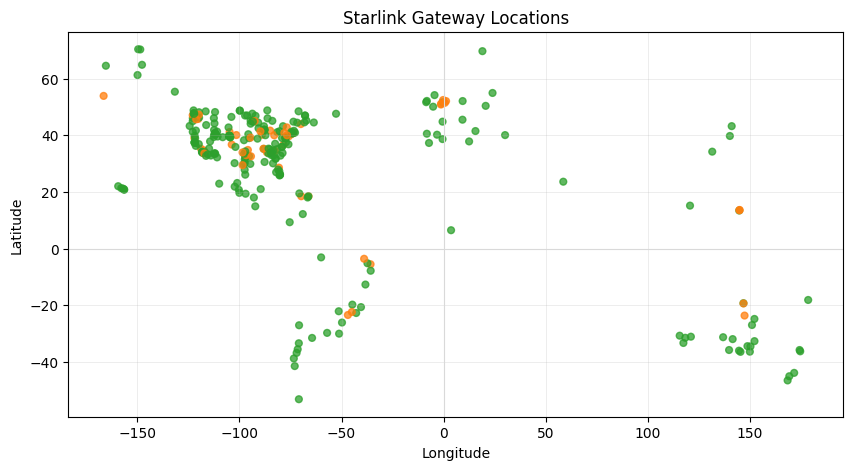

In [5]:
try:
    import matplotlib.pyplot as plt

    colors = clean_gateways["status"].map({"operational": "tab:green", "planned": "tab:orange"}).fillna("tab:blue")
    plt.figure(figsize=(10, 5))
    plt.scatter(clean_gateways["longitude"], clean_gateways["latitude"], c=colors, s=24, alpha=0.75)
    plt.axhline(0, color="0.85", linewidth=0.8)
    plt.axvline(0, color="0.85", linewidth=0.8)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Starlink Gateway Locations")
    plt.grid(True, linewidth=0.4, alpha=0.4)
    plt.show()
except ImportError:
    print("matplotlib is not installed; skipping optional map preview.")

## Save Phase 2 Output

The cleaned gateway table is saved as a CSV so that later notebooks can load it without depending on Hugging Face availability.

In [6]:
clean_gateways.to_csv(OUTPUT_CSV_PATH, index=False)

print(f"Saved clean Starlink gateway table to: {OUTPUT_CSV_PATH.resolve()}")
print(f"Rows saved: {len(clean_gateways)}")
clean_gateways.head(10)

Saved clean Starlink gateway table to: D:\University\PoliMi\courses\SWE2\SWE2-research-project\data\dataset\starlink_ground_stations\starlink_gateways_clean.csv
Rows saved: 302


,station_id,station_name,latitude,longitude,country,status,source
0,GATEWAY_0001,"Adelanto, CA",34.5828,-117.4090,US,planned,Hugging Face 28hery/starlink-ground-stations (...
1,GATEWAY_0002,"Aerzen, Germany",52.0489,9.2683,Germany,operational,Hugging Face 28hery/starlink-ground-stations (...
2,GATEWAY_0003,"Akita, Japan",39.7200,140.1024,Japan,operational,Hugging Face 28hery/starlink-ground-stations (...
3,GATEWAY_0004,"Akron, OH",41.0575,-81.5199,US,operational,Hugging Face 28hery/starlink-ground-stations (...
4,GATEWAY_0005,"Alfouvar de Cima, Portugal",40.5167,-8.2500,Portugal,operational,Hugging Face 28hery/starlink-ground-stations (...
5,GATEWAY_0006,"Anchorage, AK",61.2181,-149.9003,US,operational,Hugging Face 28hery/starlink-ground-stations (...
6,GATEWAY_0007,"Anderson, SC",34.5034,-82.6501,US,planned,Hugging Face 28hery/starlink-ground-stations (...
7,GATEWAY_0008,"Angeles, Philippines",15.1450,120.5887,Philippines,operational,Hugging Face 28hery/starlink-ground-stations (...
8,GATEWAY_0009,"Angola, IN",41.6348,-84.9994,US,planned,Hugging Face 28hery/starlink-ground-stations (...
9,GATEWAY_0010,"Arbuckle, CA",39.0200,-122.0600,US,planned,Hugging Face 28hery/starlink-ground-stations (...


## Phase 2 Result

Phase 2 produces a validated Starlink gateway table with fixed ground locations and source provenance. This table is ready to be combined with the Layer A satellite data in a later visibility-window phase after review.